In [ ]:
import os
import zipfile
import torch

# 1. Kiểm tra thiết bị phần cứng (GPU/CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"⚡ Thiết bị huấn luyện đang sử dụng: {device}")
if device.type == "cuda":
    print(f"🔥 GPU Name: {torch.cuda.get_device_name(0)}")

# 2. Giải nén file dataset.zip
zip_path = "dataset.zip"
extract_dir = "dataset_extracted"

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print(f"✅ Đã giải nén thành công vào thư mục '{extract_dir}'")
else:
    print(f"❌ Không tìm thấy file {zip_path}. Hãy đảm bảo bạn đã upload file này lên Colab.")

# 3. Định vị thư mục chứa 3 tập train, val, test
# Tìm tự động đường dẫn chứa các thư mục train, val, test
data_root = None
for root, dirs, files in os.walk(extract_dir):
    if "train" in dirs and "val" in dirs and "test" in dirs:
        data_root = root
        break

if data_root:
    print(f"📍 Đã xác định thư mục chứa dữ liệu: {data_root}")
    TRAIN_DIR = os.path.join(data_root, "train")
    VAL_DIR = os.path.join(data_root, "val")
    TEST_DIR = os.path.join(data_root, "test")
else:
    print("❌ Không tìm thấy cấu trúc thư mục train/val/test hợp lệ!")

⚡ Thiết bị huấn luyện đang sử dụng: cuda
🔥 GPU Name: Tesla T4
✅ Đã giải nén thành công vào thư mục 'dataset_extracted'
📍 Đã xác định thư mục chứa dữ liệu: dataset_extracted


In [ ]:
import json
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Tăng cường dữ liệu (Data Augmentation) cho tập Train và Normalize cho Val/Test
train_transforms = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transforms = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load Datasets
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
val_dataset = datasets.ImageFolder(VAL_DIR, transform=eval_transforms)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transforms)

# Tạo DataLoader
BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Lưu lại mapping tên nhãn để dùng khi suy luận local
class_names = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

print(f"🏷️ Danh sách 7 nhãn ({len(class_names)} classes): {class_names}")
print(f"📊 Số lượng mẫu - Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

with open("class_indices.json", "w") as f:
    json.dump(class_to_idx, f, indent=4)
print("💾 Đã lưu sơ đồ nhãn vào file 'class_indices.json'")

🏷️ Danh sách 7 nhãn (7 classes): ['crossed', 'empty_a', 'empty_b', 'empty_c', 'empty_d', 'empty_e', 'filled']
📊 Số lượng mẫu - Train: 1305 | Val: 210 | Test: 140
💾 Đã lưu sơ đồ nhãn vào file 'class_indices.json'


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class OMRPatchNet(nn.Module):
    def __init__(self, num_classes=7):
        super(OMRPatchNet, self).__init__()

        # Block 1: Input (3, 32, 32) -> Output (32, 16, 16)
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        # Block 2: Input (32, 16, 16) -> Output (64, 8, 8)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        # Block 3: Input (64, 8, 8) -> Output (128, 4, 4)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.3)

        # Fully Connected Layers
        self.fc1 = nn.Linear(128 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        x = x.view(x.size(0), -1) # Flatten
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

model = OMRPatchNet(num_classes=len(class_names)).to(device)
print(model)

OMRPatchNet(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=7, bias=True)
)


In [ ]:
import torch.optim as optim
import time

EPOCHS = 35
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

# Đã bỏ tham số 'verbose=True' để tương thích với PyTorch mới
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)

best_val_acc = 0.0
BEST_MODEL_PATH = "omr_model_best.pth"

print("🚀 BẮT ĐẦU HUẤN LUYỆN MODEL 2...")
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    # --- PHASE 1: TRAIN ---
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += (preds == labels).sum().item()
        total_train += labels.size(0)

    train_loss = running_loss / total_train
    train_acc = (correct_train / total_train) * 100.0

    # --- PHASE 2: VALIDATION ---
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += (preds == labels).sum().item()
            total_val += labels.size(0)

    val_loss = val_loss / total_val
    val_acc = (correct_val / total_val) * 100.0

    scheduler.step(val_acc)

    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% "
          f"|| Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

    # Lưu checkpoint nếu Val Accuracy đạt điểm cao nhất
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'class_to_idx': class_to_idx
        }, BEST_MODEL_PATH)
        print(f"  ⭐ Đã lưu Model xuất sắc nhất tại Epoch {epoch} (Val Acc: {val_acc:.2f}%)")

elapsed_time = time.time() - start_time
print(f"\n✅ HUẤN LUYỆN HOÀN TẤT trong {elapsed_time:.2f} giây!")
print(f"🏆 Độ chính xác cao nhất trên tập Validation: {best_val_acc:.2f}%")

🚀 BẮT ĐẦU HUẤN LUYỆN MODEL 2...
Epoch [01/35] Train Loss: 1.4774 | Train Acc: 37.47% || Val Loss: 1.2484 | Val Acc: 56.19%
  ⭐ Đã lưu Model xuất sắc nhất tại Epoch 1 (Val Acc: 56.19%)
Epoch [02/35] Train Loss: 0.9377 | Train Acc: 62.53% || Val Loss: 0.6246 | Val Acc: 82.38%
  ⭐ Đã lưu Model xuất sắc nhất tại Epoch 2 (Val Acc: 82.38%)
Epoch [03/35] Train Loss: 0.4674 | Train Acc: 82.68% || Val Loss: 0.3138 | Val Acc: 86.67%
  ⭐ Đã lưu Model xuất sắc nhất tại Epoch 3 (Val Acc: 86.67%)
Epoch [04/35] Train Loss: 0.2752 | Train Acc: 89.50% || Val Loss: 0.2062 | Val Acc: 91.90%
  ⭐ Đã lưu Model xuất sắc nhất tại Epoch 4 (Val Acc: 91.90%)
Epoch [05/35] Train Loss: 0.1950 | Train Acc: 91.11% || Val Loss: 0.1806 | Val Acc: 92.86%
  ⭐ Đã lưu Model xuất sắc nhất tại Epoch 5 (Val Acc: 92.86%)
Epoch [06/35] Train Loss: 0.1775 | Train Acc: 92.72% || Val Loss: 0.1660 | Val Acc: 96.67%
  ⭐ Đã lưu Model xuất sắc nhất tại Epoch 6 (Val Acc: 96.67%)
Epoch [07/35] Train Loss: 0.1746 | Train Acc: 92.57% || 

📊 BÁO CÁO ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP (140 ẢNH)
              precision    recall  f1-score   support

     crossed     0.9524    1.0000    0.9756        20
     empty_a     1.0000    1.0000    1.0000        20
     empty_b     1.0000    1.0000    1.0000        20
     empty_c     1.0000    0.9000    0.9474        20
     empty_d     1.0000    0.9500    0.9744        20
     empty_e     0.9091    1.0000    0.9524        20
      filled     1.0000    1.0000    1.0000        20

    accuracy                         0.9786       140
   macro avg     0.9802    0.9786    0.9785       140
weighted avg     0.9802    0.9786    0.9785       140



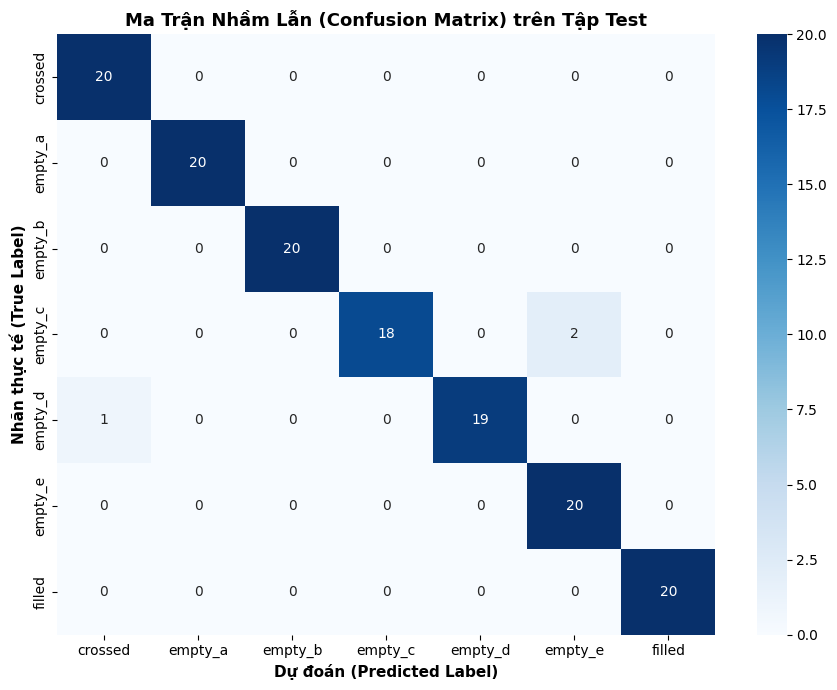

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Load lại weights xuất sắc nhất
checkpoint = torch.load(BEST_MODEL_PATH)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

# In Báo cáo Độc lập (Precision, Recall, F1-Score)
print("=========================================================")
print("📊 BÁO CÁO ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP (140 ẢNH)")
print("=========================================================")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

# Vẽ Ma Trận Nhầm Lẫn (Confusion Matrix)
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Dự đoán (Predicted Label)', fontsize=11, fontweight='bold')
plt.ylabel('Nhãn thực tế (True Label)', fontsize=11, fontweight='bold')
plt.title('Ma Trận Nhầm Lẫn (Confusion Matrix) trên Tập Test', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

In [ ]:
from google.colab import files

print("📥 Đang chuẩn bị tải các file về máy local...")

# 1. Tải file weights mô hình PyTorch (.pth)
files.download(BEST_MODEL_PATH)

# 2. Tải file JSON lưu cấu trúc mapping nhãn (class_indices.json)
files.download("class_indices.json")

# 3. Tải biểu đồ ma trận nhầm lẫn
files.download("confusion_matrix.png")

print("🎉 Hoàn tất! Bạn có thể đưa file 'omr_model_best.pth' vào thư mục 'TNAI/src/' trên máy local để chấm điểm bài thi.")

📥 Đang chuẩn bị tải các file về máy local...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

🎉 Hoàn tất! Bạn có thể đưa file 'omr_model_best.pth' vào thư mục 'TNAI/src/' trên máy local để chấm điểm bài thi.
